## Plot of combined rates for Paper

Index(['annotations', 'assignments', 'civic.evidenceDirection',
       'civic.evidenceLevel', 'civic.evidenceRating', 'civic.flagged',
       'civic.id', 'civic.status', 'claim.flat', 'claim.source', 'comments',
       'document.content_source', 'document.content_source_x', 'document.doi',
       'document.length', 'document.license', 'document.pmcid',
       'document.pmid', 'document.title', 'document.total_chunks',
       'evidence.flat', 'evidence_chunks', 'generated_text', 'gold_label_name',
       'is_committee', 'meta', 'model', 'partition', 'predicted_label_name',
       'project', 'prompt', 'response', 'review_id', 'review_round', 'score',
       'tag_status', 'tags', 'template', 'text', 'username'],
      dtype='object')


,tags_x,tags_y,tag_status_x,tag_status_y
91,"{Helpful, Incomplete}","{Helpful, Incomplete, External Inconsistency}",Helpful (Minor Issues),Major Issues
124,{Helpful},"{Helpful, Incomplete}",Helpful,Helpful (Minor Issues)


<Figure size 1000x600 with 0 Axes>

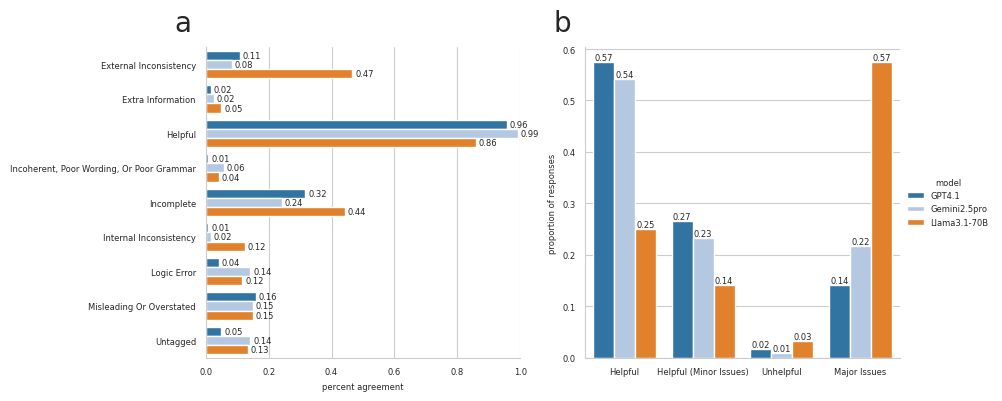

In [4]:
## Now make the combined plot for the paper
from matplotlib import pyplot as plt
from figutils.util import generate_hue_map
import seaborn as sns
import os

from figutils import add_bar_labels
from article_utils.util import read_jsonl
from iaa import classify_problem

def relative_file(filename):
    return os.path.join('..', 'data/doccano/2025.05.01_llm_explanation_quality_v2025.03.25', filename)

sns.set_style('whitegrid')

def combine_tags(tag_lists):
    tags= set()
    for tag_set in tag_lists:
        tags.update(tag_set)
    return tags

tags_df = read_jsonl(relative_file('processed/explanation_tags.jsonl.gz'))

cons_df = read_jsonl(relative_file('processed/gold_labels.jsonl.gz')).drop_duplicates(['review_id'])
cons_df = cons_df[[c for c in cons_df.columns if c.startswith('consensus.')] + ['review_id', 'prompt', 'evidence.flat', 'claim.flat', 'admin_flags', 'gold_label_name']]
cons_df = cons_df.drop_duplicates('review_id')

print(tags_df.columns)
tags_df['response_id'] = tags_df.review_id + ' ' + tags_df.response.str['start'].astype(str)
tags_df['tags'] = tags_df.tags.apply(lambda t: set(t))
tags_df = tags_df.merge(cons_df[['consensus.gold_label_name', 'gold_label_name', 'review_id']], how='left')

round3_df = tags_df[(tags_df.review_round.str.contains('3')) & (~tags_df.model.str.contains('old'))].copy()
round3_df['orig_tag_tup'] = round3_df.tags.apply(lambda tags: tuple(sorted(tags)))

pre_df = round3_df[round3_df.model == 'GPT4.1'].copy()

round3_df = round3_df.groupby(['response_id', 'model', 'consensus.gold_label_name', 'review_id', 'predicted_label_name', 'gold_label_name'], dropna=False).agg({'tags': combine_tags}).reset_index()
round3_df['tag_status'] = round3_df.tags.apply(classify_problem)
round3_df['tag_tup'] = round3_df.tags.apply(lambda tags: tuple(sorted(tags)))
round3_df = round3_df[round3_df.model != 'Llama3.1-8B FT']

comp_df = pre_df.merge(round3_df, on=['response_id', 'model'])
comp_df['lost_tags'] = comp_df['tags_x'] - comp_df['tags_y']
comp_df['new_tags'] = comp_df['tags_y'] - comp_df['tags_x']


fig = plt.figure(figsize=(10, 6), layout='tight')

# gs = gridspec.GridSpec(1, 2, figure=fig)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), layout='tight')
hue_map = generate_hue_map(sorted(round3_df.model.unique()), 'tab20')

fig_df = round3_df.copy().explode('tags').reset_index(drop=True)
fig_df = fig_df.drop_duplicates(['tags', 'response_id', 'model'])
fig_df['freq'] = 1
fig_df = fig_df.merge(round3_df.groupby('model').agg({'response_id': 'nunique'}).reset_index().rename(columns={'response_id': 'total_resps'}))
fig_df = fig_df.groupby(['total_resps', 'model', 'tags']).agg({'response_id': 'nunique'}).reset_index()
fig_df['rate'] = fig_df.response_id / fig_df.total_resps

ax1 = sns.barplot(fig_df, y='tags', hue='model', x='rate', palette=hue_map, ax=ax1)
ax1.set_xlim(0,1)
add_bar_labels(ax1, fmt=lambda x: round(x, 2), padding=2)
ax1.set_ylabel('')
ax1.set_xlabel('percent agreement')


fig_df = round3_df.copy()
fig_df = fig_df.drop_duplicates(['tag_status', 'response_id', 'model'])
fig_df['freq'] = 1
fig_df = fig_df.merge(round3_df.groupby('model').agg({'response_id': 'nunique'}).reset_index().rename(columns={'response_id': 'total_resps'}))
fig_df= fig_df.groupby(['total_resps', 'model', 'tag_status']).agg({'response_id': 'nunique'}).reset_index()
fig_df['rate'] = fig_df.response_id / fig_df.total_resps
x_order = ['Helpful', 'Helpful (Minor Issues)', 'Unhelpful', 'Major Issues']
fig_df['x_order'] = fig_df.tag_status.apply(lambda x: x_order.index(x))
fig_df = fig_df.sort_values('x_order')

ax2 = sns.barplot(fig_df, x='tag_status', hue='model', y='rate', palette=hue_map, ax=ax2)
add_bar_labels(ax2, fmt=lambda x: round(x, 2))
ax2.set_xlabel('')
ax2.set_ylabel('proportion of responses')
ax1.legend_.remove()
sns.move_legend(ax2, "center left", bbox_to_anchor=(1,0.5), frameon=False)

for char, ax in zip('ab', (ax1, ax2)):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_title(char, fontsize=20, loc='left', x=-0.1, y=1.025)

comp_df[comp_df.tag_status_x != comp_df.tag_status_y][['tags_x', 'tags_y', 'tag_status_x', 'tag_status_y']]

## Investigating Snowballing

Do we detect more errors when the label is wrong? does this cross models?


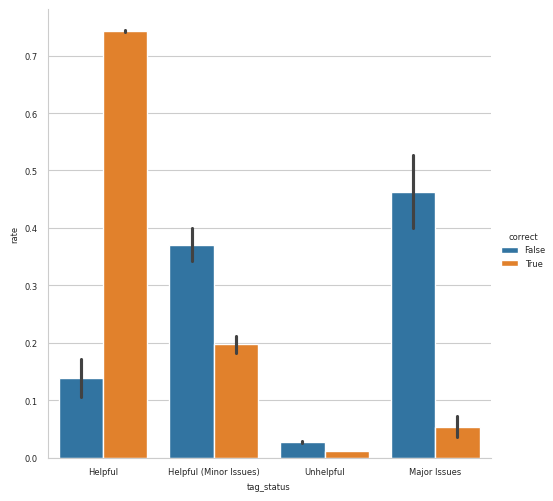

In [2]:
fig_df = round3_df.copy()
fig_df['correct'] = fig_df.predicted_label_name == fig_df['consensus.gold_label_name']
fig_df.head()

resp_total = fig_df.groupby(['correct', 'model']).agg({'response_id': 'nunique'}).reset_index().rename(columns={'response_id': 'split_total'})

fig_df = fig_df.groupby(['tag_status', 'model', 'correct']).agg({'response_id': 'nunique'}).reset_index().merge(resp_total)
fig_df['rate'] = fig_df.response_id /fig_df.split_total
fig_df['x_order'] = fig_df.tag_status.apply(lambda x: x_order.index(x))
fig_df = fig_df.sort_values('x_order')

sns.catplot(fig_df[~fig_df.model.str.contains('Llama')], kind='bar', x='tag_status', y='rate', hue='correct', errorbar=lambda ser: (ser.min(), ser.max()))